In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

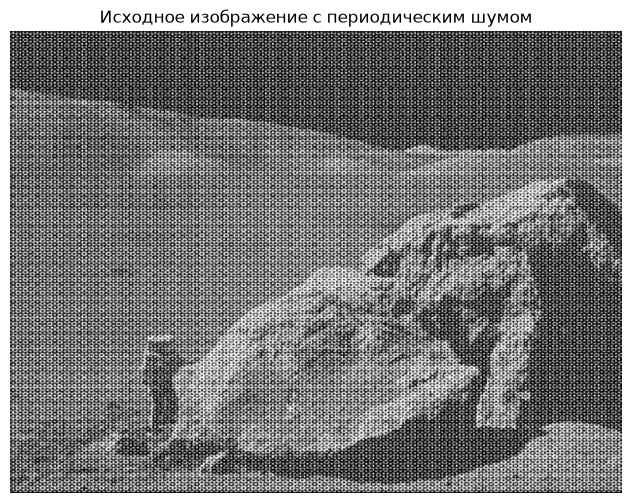

Размер изображения: (594, 787)


In [2]:
from pathlib import Path

image = cv2.imread(
    str(Path.home() / 'Desktop' / 'periodic_noise.JPG'),
    cv2.IMREAD_GRAYSCALE
)

if image is None:
    raise FileNotFoundError('Изображение не найдено на рабочем столе')

plt.figure(figsize=(10, 6))
plt.imshow(image, cmap='gray')
plt.title('Исходное изображение с периодическим шумом')
plt.axis('off')
plt.show()

print('Размер изображения:', image.shape)

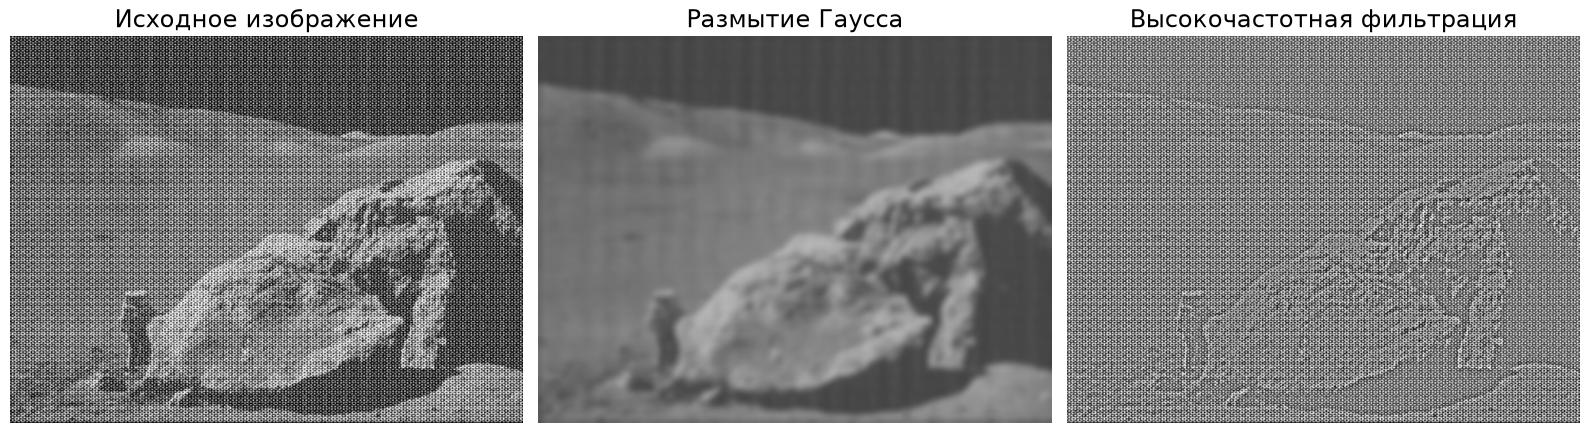

In [11]:
#Размытая версия изображения
blurred = cv2.GaussianBlur(image, (21, 21), 5)

#Высокочастотная составляющая
high_freq = image.astype(np.float32) - blurred.astype(np.float32)

high_freq_display = np.clip(
    high_freq + 128, 0, 255
).astype(np.uint8)

plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray', vmin=0, vmax=255)
plt.title('Исходное изображение', fontsize=17)
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(blurred, cmap='gray', vmin=0, vmax=255)
plt.title('Размытие Гаусса', fontsize=17)
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(high_freq_display, cmap='gray', vmin=0, vmax=255)
plt.title('Высокочастотная фильтрация', fontsize=17)
plt.axis('off')

plt.tight_layout()
plt.show()

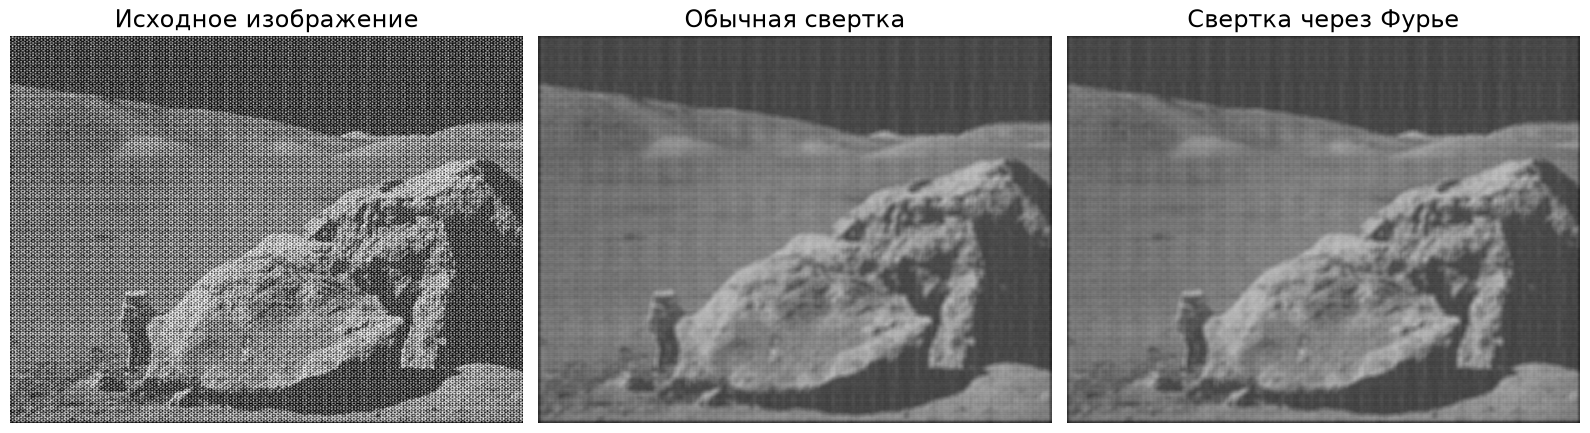

Результаты сравнения сверток:
Средняя яркость после пространственной свертки: 107.20585
Средняя яркость после свертки через Фурье: 107.20585
Максимальная разница между результатами: 0.00012207031


In [16]:
kernel = np.ones((9, 9), dtype=np.float32) / 81
#Обычная свертка
image_float = image.astype(np.float32)

spatial_result = cv2.filter2D(
    image_float, -1, kernel,
    borderType=cv2.BORDER_CONSTANT
)
#Свертка с помощью преобразования Фурье
height, width = image.shape
kh, kw = kernel.shape

fft_height = height + kh - 1
fft_width = width + kw - 1

image_fft = np.fft.fft2(
    image_float, s=(fft_height, fft_width)
)

kernel_fft = np.fft.fft2(
    kernel, s=(fft_height, fft_width)
)

convolution_full = np.fft.ifft2(
    image_fft * kernel_fft
).real

start_y = kh // 2
start_x = kw // 2

fourier_result = convolution_full[
    start_y:start_y + height,
    start_x:start_x + width
]

plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray', vmin=0, vmax=255)
plt.title('Исходное изображение', fontsize=17)
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(spatial_result, cmap='gray', vmin=0, vmax=255)
plt.title('Обычная свертка', fontsize=17)
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(fourier_result, cmap='gray', vmin=0, vmax=255)
plt.title('Свертка через Фурье', fontsize=17)
plt.axis('off')

plt.tight_layout()
plt.show()

print('Результаты сравнения сверток:')
print('Средняя яркость после пространственной свертки:',
      np.mean(spatial_result))
print('Средняя яркость после свертки через Фурье:',
      np.mean(fourier_result))
print('Максимальная разница между результатами:',
      np.max(np.abs(spatial_result - fourier_result)))


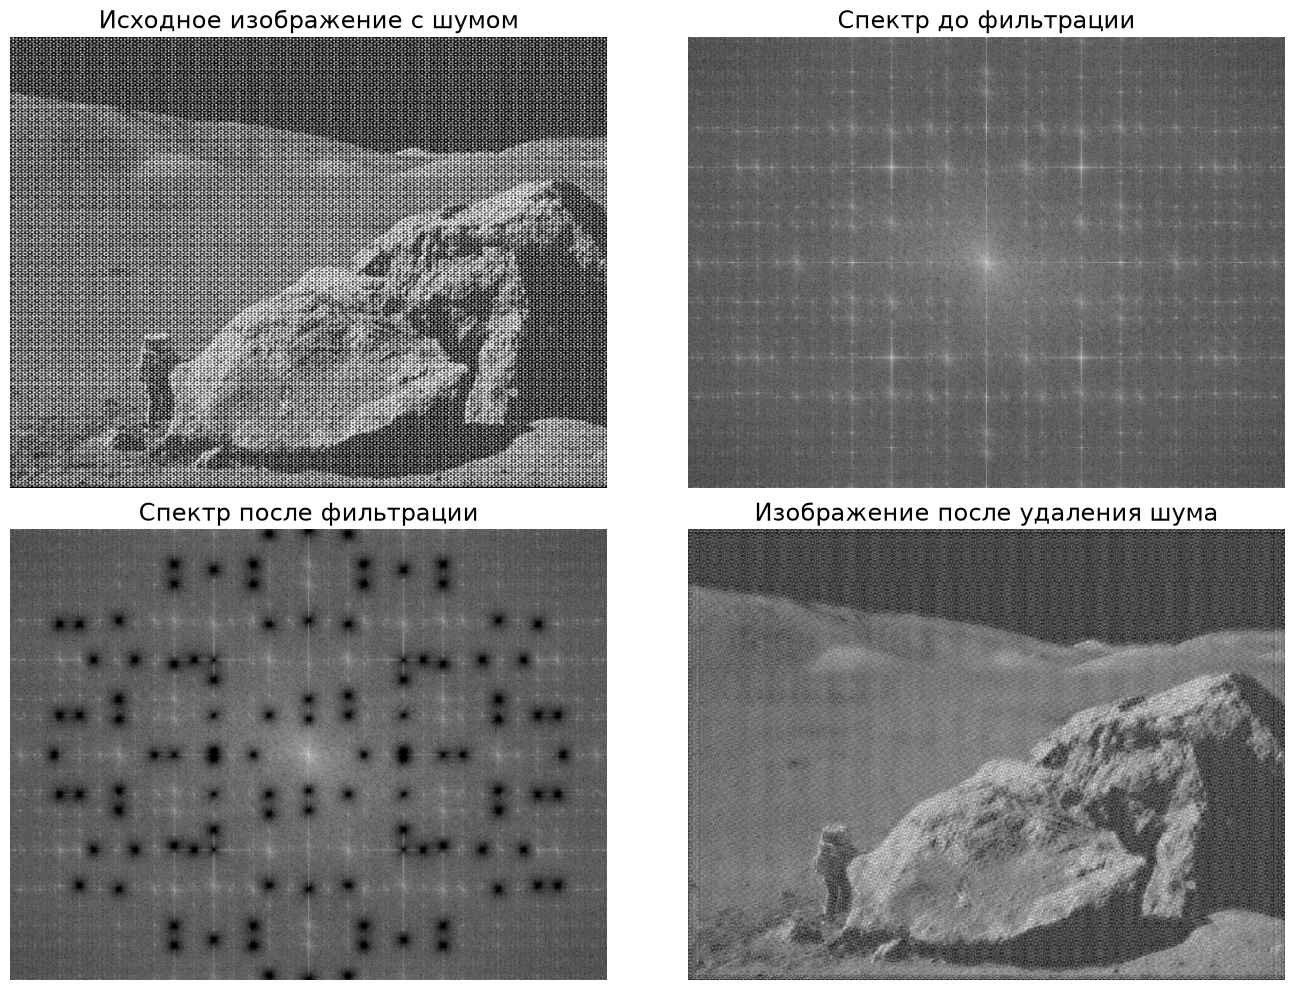

Количество обнаруженных частотных помех: 108


In [27]:
noise_dft = cv2.dft(
    np.float32(image),
    flags=cv2.DFT_COMPLEX_OUTPUT
)

noise_dft_shift = np.fft.fftshift(
    noise_dft,
    axes=(0, 1)
)

noise_magnitude = cv2.magnitude(
    noise_dft_shift[:, :, 0],
    noise_dft_shift[:, :, 1]
)

noise_spectrum = 20 * np.log1p(noise_magnitude)

height, width = image.shape
center_y = height // 2
center_x = width // 2

spectrum = np.log1p(noise_magnitude)

spectrum_background = cv2.GaussianBlur(
    spectrum, (0, 0), 9
)

peaks_strength = spectrum - spectrum_background

peaks_strength[
    center_y-32:center_y+33,
    center_x-32:center_x+33
] = 0

local_max = cv2.dilate(
    peaks_strength,
    np.ones((13, 13), dtype=np.uint8)
)

peaks = (
    (peaks_strength >= local_max - 0.000001) &
    (peaks_strength > 3.5)
)

peak_y, peak_x = np.where(peaks)

mask = np.ones((height, width), dtype=np.float32)

y, x = np.ogrid[:height, :width]
radius = 10

for py, px in zip(peak_y, peak_x):
    for yy, xx in [
        (py, px),
        ((2 * center_y - py) % height,
         (2 * center_x - px) % width)
    ]:
        distance_squared = (y - yy)**2 + (x - xx)**2

        notch = 1 - np.exp(
            -distance_squared / (2 * radius**2)
        )

        mask *= notch

filtered_spectrum = noise_dft_shift * mask[:, :, np.newaxis]

filtered_magnitude = cv2.magnitude(
    filtered_spectrum[:, :, 0],
    filtered_spectrum[:, :, 1]
)

filtered_spectrum_view = 20 * np.log1p(filtered_magnitude)

filtered_shift = np.fft.ifftshift(
    filtered_spectrum, axes=(0, 1)
)

restored_image = cv2.idft(
    filtered_shift,
    flags=cv2.DFT_SCALE | cv2.DFT_REAL_OUTPUT
)

restored_image = np.clip(
    restored_image, 0, 255
).astype(np.uint8)

plt.figure(figsize=(14, 10))

plt.subplot(2, 2, 1)
plt.imshow(image, cmap='gray', vmin=0, vmax=255)
plt.title('Исходное изображение с шумом', fontsize=17)
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(noise_spectrum, cmap='gray')
plt.title('Спектр до фильтрации', fontsize=17)
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(
    filtered_spectrum_view,
    cmap='gray',
    vmin=np.min(noise_spectrum),
    vmax=np.max(noise_spectrum)
)
plt.title('Спектр после фильтрации', fontsize=17)
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(restored_image, cmap='gray', vmin=0, vmax=255)
plt.title('Изображение после удаления шума', fontsize=17)
plt.axis('off')

plt.tight_layout()
plt.show()

print('Количество обнаруженных частотных помех:', len(peak_y))